In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

df = pd.read_csv("Housing.csv")


X = df.iloc[:, 1]
y = df.iloc[:, 0]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

X_mean = X_train.mean()
X_sd = X_train.std()

y_mean = y_train.mean()
y_sd = y_train.std()

X_train_scaled = (X_train - X_mean) / X_sd
X_test_scaled = (X_test - X_mean) / X_sd

y_train_scaled = (y_train - y_mean) / y_sd
y_test_scaled = (y_test - y_mean) / y_sd


print(X,y)
print(X_test,y_test)

0      7420
1      8960
2      9960
3      7500
4      7420
       ... 
540    3000
541    2400
542    3620
543    2910
544    3850
Name: area, Length: 545, dtype: int64 0      13300000
1      12250000
2      12250000
3      12215000
4      11410000
         ...   
540     1820000
541     1767150
542     1750000
543     1750000
544     1750000
Name: price, Length: 545, dtype: int64
316    5900
77     6500
360    4040
90     5000
493    3960
       ... 
15     6000
357    6930
39     6000
54     6000
155    6100
Name: area, Length: 109, dtype: int64 316    4060000
77     6650000
360    3710000
90     6440000
493    2800000
        ...   
15     9100000
357    3773000
39     7910000
54     7350000
155    5530000
Name: price, Length: 109, dtype: int64


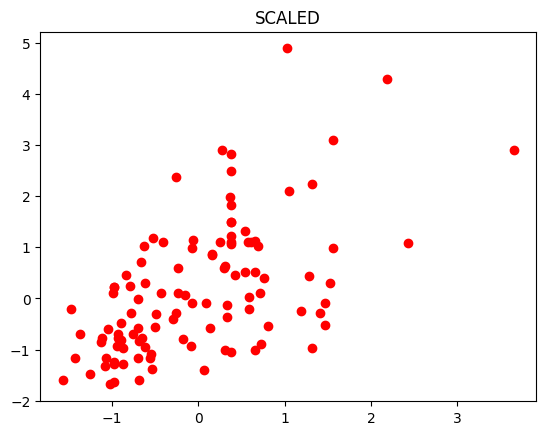

In [31]:
plt.title("SCALED")
plt.scatter(X_test_scaled,y_test_scaled,color="red")


Text(0.5, 1.0, 'UNSCALED')

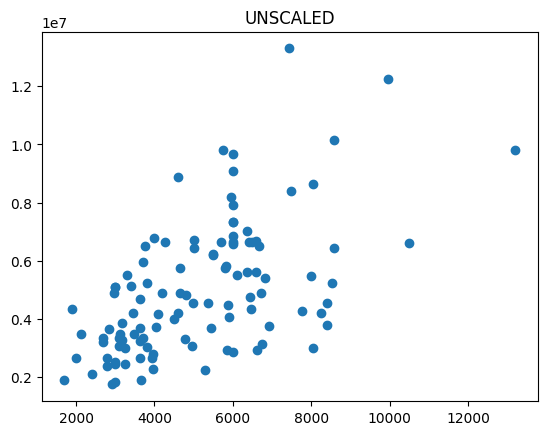

In [30]:
plt.scatter(X_test,y_test)
plt.title("UNSCALED")

##GRADIENT DESCENT

In [ ]:
def gradient_descent(X, y, learning_rate=0.00001, iterations=1000):

    m = len(X)
    w = 0.0
    b = 0.0

    cost_history = []

    for i in range(iterations):

        y_pred = w * X + b

        dw = (1/m) * np.sum((y_pred - y) * X)
        db = (1/m) * np.sum(y_pred - y)

        w = w - learning_rate * dw
        b = b - learning_rate * db

        cost = (1/(2*m)) * np.sum((y_pred - y)**2)
        cost_history.append(cost)

    return w, b, cost_history

In [ ]:
w1, b1, cost1 = gradient_descent(
    X_train, y_train,
    learning_rate=0.00000001,
    iterations=1000
)

pred1 = w1 * X_test + b1

In [29]:
w2, b2, cost2 = gradient_descent(
    X_train_scaled, y_train,
    learning_rate=0.01,
    iterations=1000
)

pred2 = w2 * X_test_scaled + b2

In [24]:
print("UNSCALED MODEL")
print("MSE:", mean_squared_error(y_test, pred1))
print("R2:", r2_score(y_test, pred1))

print("\nSCALED MODEL")
print("MSE:", mean_squared_error(y_test, pred2))
print("R2:", r2_score(y_test, pred2))


UNSCALED MODEL
MSE: 4068148472257.008
R2: 0.19515442975852193

SCALED MODEL
MSE: 3675444093746.636
R2: 0.2728473609811505


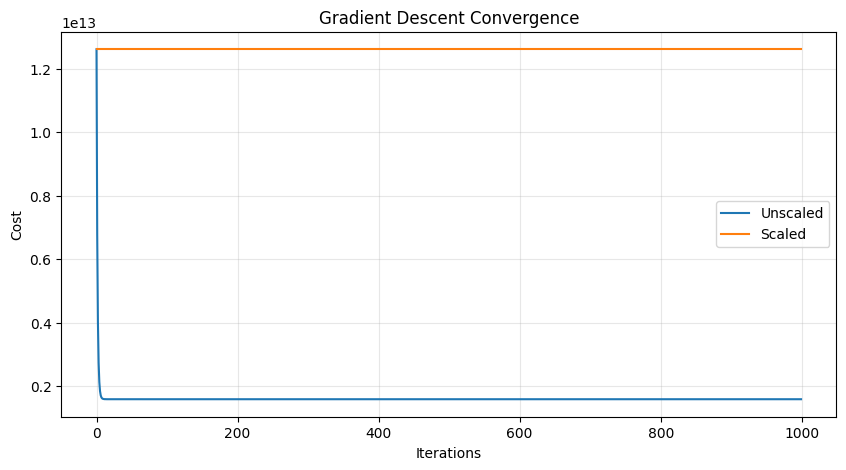

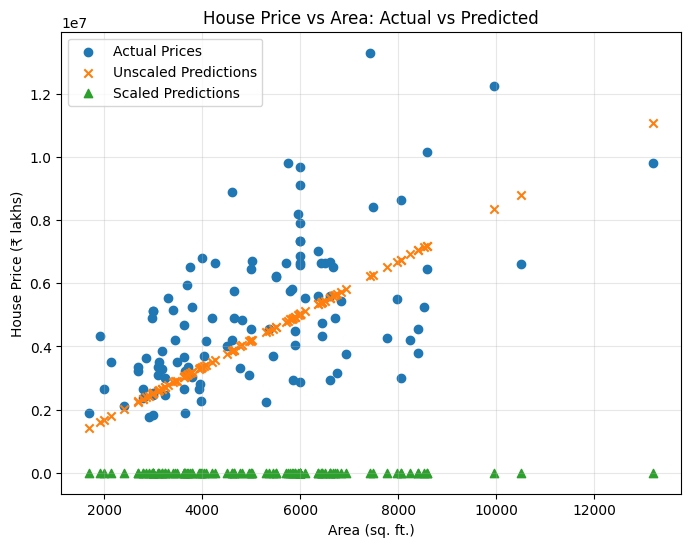

In [ ]:
#COST COMPARISION

plt.figure(figsize=(10, 5))

plt.plot(cost1, label="Unscaled")
plt.plot(cost2, label="Scaled")

plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title("Gradient Descent Convergence")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# PREDICTION COMPARISON

plt.figure(figsize=(8, 6))

plt.scatter(X_test, y_test, label="Actual Prices", marker="o")
plt.scatter(X_test, pred1, label="Unscaled Predictions", marker="x")
plt.scatter(X_test, pred2, label="Scaled Predictions", marker="^")

plt.xlabel("Area (sq. ft.)")
plt.ylabel("House Price (₹ lakhs)")
plt.title("House Price vs Area: Actual vs Predicted")

plt.legend()
plt.grid(alpha=0.3)
plt.show()
